# Task C — Palette simulation, step by step

CDB601220 · Week 3. Work through the cells from top to bottom. Every dataset is loaded from the **data/** folder beside this notebook. All data are synthetic, supplied with the assignment. Charts and written answers stay inside the notebook; no output files are created.

## 1. Import libraries and locate the data folder

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

DATA = Path('data')
assert DATA.is_dir(), 'Open this notebook inside task3, beside the data folder.'
sns.set_theme(style='whitegrid', palette=['#0072B2', '#D55E00', '#009E73'])
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.ioff()
BLUE, ORANGE, GREEN = '#0072B2', '#D55E00', '#009E73'
SOURCE = 'Source: synthetic CDB601220 Week 3 assignment data.'

This task uses palettes and simulation matrices, so it does **not** need a CSV. The steps below write out the supplied toolkit’s Machado severity-1.0 simulation and OKLab distance calculations, without wrapping the task in a function.

## C1. Choose a candidate palette and the course palette

In [2]:
from matplotlib.colors import to_rgb
from itertools import combinations

palettes = {
    'Candidate tab10': ['#1F77B4', '#FF7F0E', '#2CA02C', '#D62728'],
    'Course + fourth': ['#0072B2', '#D55E00', '#009E73', '#CC79A7']
}
display(pd.DataFrame(palettes, index=['S1', 'S2', 'S3', 'S4']))

,Candidate tab10,Course + fourth
S1,#1F77B4,#0072B2
S2,#FF7F0E,#D55E00
S3,#2CA02C,#009E73
S4,#D62728,#CC79A7


The candidate was selected for visual variety, without assuming it is accessible. Test normal vision and deutan, protan and tritan simulations for **both** palettes.

### Enter the supplied simulation matrices

In [3]:
cvd_matrices = {
 'deutan': np.array([[.367322,.860646,-.227968], [.280085,.672501,.047413], [-.011820,.042940,.968881]]),
 'protan': np.array([[.152286,1.052583,-.204868], [.114503,.786281,.099216], [-.003882,-.048116,1.051998]]),
 'tritan': np.array([[1.255528,-.076749,-.178779], [-.078411,.930809,.147602], [.004733,.691367,.303900]])
}
rgb_palettes = {name:np.array([to_rgb(h) for h in colors]) for name, colors in palettes.items()}

### Convert sRGB into linear light and apply each matrix

In [4]:
simulated = {}
for name, rgb in rgb_palettes.items():
    linear = np.where(rgb <= .04045, rgb/12.92, ((rgb+.055)/1.055)**2.4)
    simulated[(name, 'normal')] = rgb
    for kind, matrix in cvd_matrices.items():
        changed = np.clip(linear @ matrix.T, 0, 1)
        srgb = np.where(changed <= .0031308, 12.92*changed, 1.055*changed**(1/2.4)-.055)
        simulated[(name, kind)] = np.round(srgb*255)/255
print('Simulated views:', len(simulated))

Simulated views: 8


The round-to-8-bit step matches the toolkit’s hex-color output. Applying the matrices directly to gamma-encoded sRGB would give the wrong result.

## C2. Compare the before/after swatches

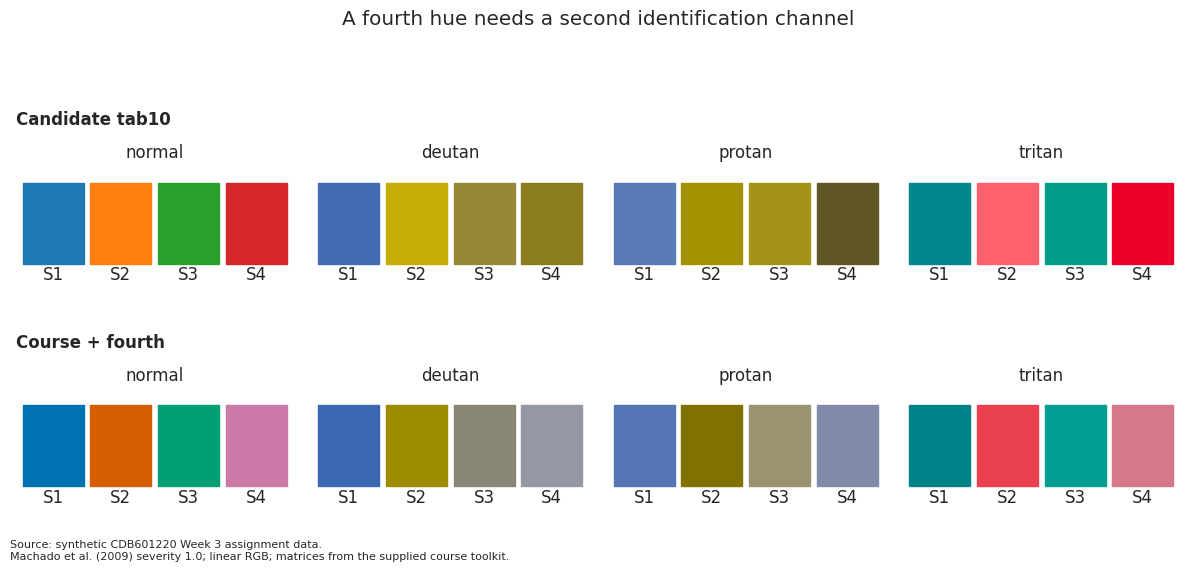

In [5]:
visions = ['normal', 'deutan', 'protan', 'tritan']
fig, ax = plt.subplots(2, 4, figsize=(12, 5))
for row, name in enumerate(palettes):
    for col, kind in enumerate(visions):
        a = ax[row, col]
        for slot, rgb in enumerate(simulated[(name, kind)]):
            a.add_patch(plt.Rectangle((slot, 0), .9, 1, color=rgb))
            a.text(slot+.45, -.2, f'S{slot+1}', ha='center')
        a.set(xlim=(-.1,4), ylim=(-.5,1.2), title=kind)
        a.axis('off')
        if col == 0:
            a.text(0, 1.3, name, transform=a.transAxes, fontweight='bold')
fig.suptitle('A fourth hue needs a second identification channel', y=1.07)
fig.text(0.01, -0.03, SOURCE + '\n' + 'Machado et al. (2009) severity 1.0; linear RGB; matrices from the supplied course toolkit.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

## C3. Convert simulated colors to perceptual OKLab coordinates

In [6]:
M1 = np.array([[.4122214708,.5363325363,.0514459929],
               [.2119034982,.6806995451,.1073969566],
               [.0883024619,.2817188376,.6299787005]])
M2 = np.array([[.2104542553,.7936177850,-.0040720468],
               [1.9779984951,-2.4285922050,.4505937099],
               [.0259040371,.7827717662,-.8086757660]])
oklab = {}
for key, rgb in simulated.items():
    linear = np.where(rgb <= .04045, rgb/12.92, ((rgb+.055)/1.055)**2.4)
    oklab[key] = np.cbrt(linear @ M1.T) @ M2.T

### Find the worst-separated pair in every view

In [7]:
audit_rows = []
for (name, kind), lab in oklab.items():
    distances = [(100*np.linalg.norm(lab[i]-lab[j]), i+1, j+1)
                 for i, j in combinations(range(4), 2)]
    distance, i, j = min(distances)
    verdict = 'clear' if distance >= 15 else 'ok' if distance >= 8 else 'second channel needed' if distance >= 6 else 'FAIL'
    audit_rows.append({'palette':name, 'vision':kind, 'pair':f'S{i}/S{j}',
                       'delta_E':distance, 'verdict':verdict})
audit = pd.DataFrame(audit_rows)
display(audit.round({'delta_E':3}))

,palette,vision,pair,delta_E,verdict
0,Candidate tab10,normal,S2/S4,18.598,clear
1,Candidate tab10,deutan,S3/S4,4.059,FAIL
2,Candidate tab10,protan,S2/S3,0.681,FAIL
3,Candidate tab10,tritan,S1/S3,6.721,second channel needed
4,Course + fourth,normal,S2/S4,16.420,clear
5,Course + fourth,deutan,S3/S4,7.547,second channel needed
6,Course + fourth,protan,S1/S4,9.494,ok
7,Course + fourth,tritan,S1/S3,8.372,ok


### Report the overall worst pair for each palette

In [8]:
worst = audit.loc[audit.groupby('palette').delta_E.idxmin()]
display(worst.round({'delta_E':3}))

,palette,vision,pair,delta_E,verdict
2,Candidate tab10,protan,S2/S3,0.681,FAIL
5,Course + fourth,deutan,S3/S4,7.547,second channel needed


**Answer:** Candidate tab10 collapses most at **S2/S3 under protan, ΔE≈0.68**. The course palette’s closest pair is **S3/S4 under deutan, ΔE≈7.55**. The fourth slot therefore needs direct labels or a table and a second channel such as marker shape. The supplied CVD target is ΔE≥8; values 6–8 need redundant coding, and <6 fail.

## C4. Rule for more than three categories

Use **facets, direct labels, different marker shapes, line styles or textures**. Do not rely on adding more colors. If the fourth course color is used, provide labels/table and redundant coding. Simulation is evidence under this specific model, not a guarantee for every viewer and display.